In [8]:
print("Building and Evaluating Trustworthy AI Systems")

Building and Evaluating Trustworthy AI Systems


In [9]:
%pip -q install diffprivlib fairlearn

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from diffprivlib.models import LogisticRegression as DPLogisticRegression
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

2. Generate synthetic data

In [11]:
n = 2500
gender = rng.choice(["Group A", "Group B"], size=n, p=[0.70, 0.30])
age = np.clip(rng.normal(39, 12, n), 18, 75)
income = np.clip(rng.lognormal(10.65, 0.55, n), 18000, 180000)
credit_history = rng.choice(["Good", "Limited", "Poor"], size=n, p=[0.58, 0.27, 0.15])

income_score = (income - income.min()) / (income.max() - income.min())
age_score = (age - age.min()) / (age.max() - age.min())
credit_score = pd.Series(credit_history).map({"Good": 0.8, "Limited": 0.45, "Poor": 0.15}).to_numpy()
gender_penalty = np.where(gender == "Group B", -0.65, 0.0)
logit = -0.45 + 2.1*income_score + 0.45*age_score + 1.15*credit_score + gender_penalty
probability = 1 / (1 + np.exp(-logit))
approved = rng.binomial(1, probability)

df = pd.DataFrame({"age": age, "income": income, "gender": gender,
                   "credit_history": credit_history, "loan_approved": approved})

# Introduce a small amount of missing predictor data.
for col in ["age", "income", "gender", "credit_history"]:
    missing = rng.choice(df.index, size=int(0.02*n), replace=False)
    df.loc[missing, col] = np.nan

print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nOutcome proportions:\n", df.loan_approved.value_counts(normalize=True))
print("\nGender counts:\n", df.gender.value_counts(dropna=False))
df.head()

Shape: (2500, 5)

Missing values:
 age               50
income            50
gender            50
credit_history    50
loan_approved      0
dtype: int64

Outcome proportions:
 loan_approved
1    0.6444
0    0.3556
Name: proportion, dtype: float64

Gender counts:
 gender
Group A    1702
Group B     748
NaN          50
Name: count, dtype: int64


,age,income,gender,credit_history,loan_approved
0,34.486750,90380.407787,Group B,Poor,1
1,33.503018,51275.248290,Group A,Good,0
2,48.227590,41609.681766,Group B,Good,1
3,48.829250,67124.920999,Group A,Good,1
4,32.578954,78549.455892,Group A,Good,1


3. Preprocess data

In [12]:
data = df.copy()
for col in ["age", "income"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
    data[col] = data[col].fillna(data[col].median())
for col in ["gender", "credit_history"]:
    data[col] = data[col].fillna(data[col].mode(dropna=True)[0])

scaler = MinMaxScaler()
data[["age", "income"]] = scaler.fit_transform(data[["age", "income"]])
sensitive_gender = data["gender"].copy()
X = pd.get_dummies(data[["age", "income", "gender", "credit_history"]],
                   columns=["gender", "credit_history"], dtype=int)
y = data["loan_approved"].astype(int)
print("Features:", X.columns.tolist())
print("Missing values after processing:", X.isna().sum().sum())

Features: ['age', 'income', 'gender_Group A', 'gender_Group B', 'credit_history_Good', 'credit_history_Limited', 'credit_history_Poor']
Missing values after processing: 0


Split Data 80/20

In [13]:
X_train, X_test, y_train, y_test, gender_train, gender_test = train_test_split(
    X, y, sensitive_gender, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train outcome proportions:\n", y_train.value_counts(normalize=True))
print("Test outcome proportions:\n", y_test.value_counts(normalize=True))

Train rows: 2000 | Test rows: 500
Train outcome proportions:
 loan_approved
1    0.6445
0    0.3555
Name: proportion, dtype: float64
Test outcome proportions:
 loan_approved
1    0.644
0    0.356
Name: proportion, dtype: float64


Training and Evaluate

In [14]:
tree_model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

def print_metrics(y_true, y_pred, label):
    print(f"--- {label} ---")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"F1-score : {f1_score(y_true, y_pred, zero_division=0):.3f}")
    print(classification_report(y_true, y_pred, zero_division=0))

print_metrics(y_test, tree_pred, "Decision tree")
print("Confusion matrix:\n", confusion_matrix(y_test, tree_pred))

--- Decision tree ---
Accuracy : 0.630
Precision: 0.673
Recall   : 0.829
F1-score : 0.743
              precision    recall  f1-score   support

           0       0.47      0.27      0.34       178
           1       0.67      0.83      0.74       322

    accuracy                           0.63       500
   macro avg       0.57      0.55      0.54       500
weighted avg       0.60      0.63      0.60       500

Confusion matrix:
 [[ 48 130]
 [ 55 267]]


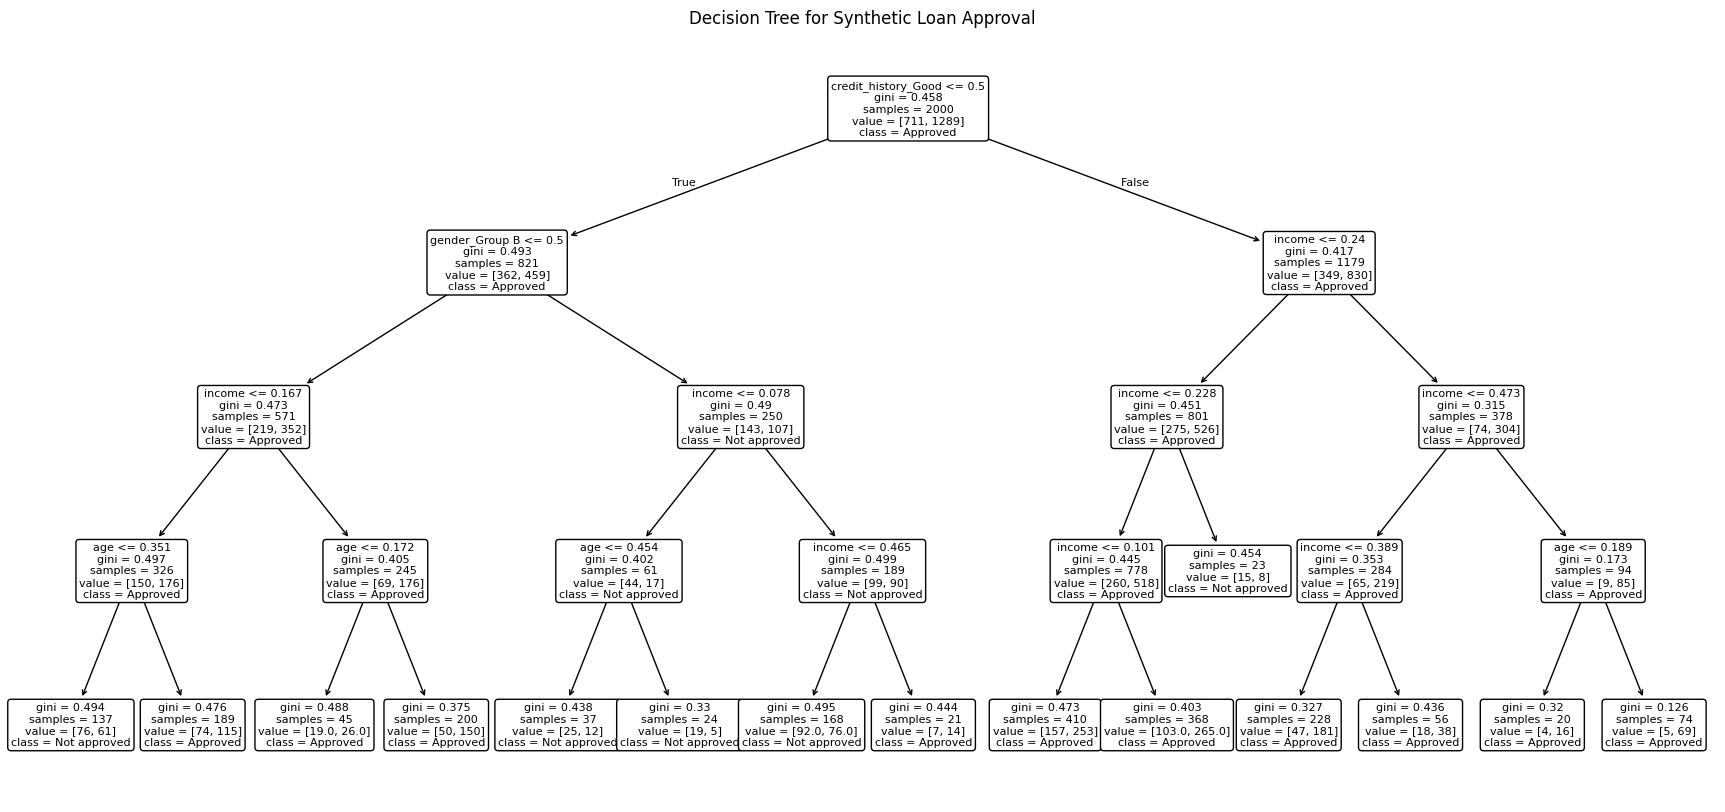

In [15]:
plt.figure(figsize=(22, 10))
plot_tree(tree_model, feature_names=X.columns, class_names=["Not approved", "Approved"],
          filled=False, rounded=True, fontsize=8)
plt.title("Decision Tree for Synthetic Loan Approval")
plt.show()

In [16]:
def fairness_summary(y_true, y_pred, groups, title):
    frame = MetricFrame(
        metrics={"selection_rate": selection_rate, "accuracy": accuracy_score},
        y_true=np.asarray(y_true), y_pred=np.asarray(y_pred),
        sensitive_features=np.asarray(groups)
    )
    print(title)
    print(frame.by_group)
    print("Demographic parity difference:",
          demographic_parity_difference(y_true=np.asarray(y_true),
                                        y_pred=np.asarray(y_pred),
                                        sensitive_features=np.asarray(groups)))
    return frame

baseline_fairness = fairness_summary(y_test, tree_pred, gender_test, "Before mitigation")

Before mitigation
                     selection_rate  accuracy
sensitive_feature_0                          
Group A                    0.878531  0.658192
Group B                    0.589041  0.561644
Demographic parity difference: 0.28948997755591666


In [17]:
fair_model = ExponentiatedGradient(
    estimator=DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE),
    constraints=DemographicParity()
)
fair_model.fit(X_train, y_train, sensitive_features=gender_train)
fair_pred = fair_model.predict(X_test)
print_metrics(y_test, fair_pred, "Fairlearn mitigated model")
mitigated_fairness = fairness_summary(y_test, fair_pred, gender_test, "After mitigation")

--- Fairlearn mitigated model ---
Accuracy : 0.622
Precision: 0.664
Recall   : 0.835
F1-score : 0.740
              precision    recall  f1-score   support

           0       0.44      0.24      0.31       178
           1       0.66      0.84      0.74       322

    accuracy                           0.62       500
   macro avg       0.55      0.54      0.52       500
weighted avg       0.59      0.62      0.59       500

After mitigation
                     selection_rate  accuracy
sensitive_feature_0                          
Group A                    0.813559  0.638418
Group B                    0.801370  0.582192
Demographic parity difference: 0.012189459020199744


In [18]:
dp_model = DPLogisticRegression(
    epsilon=1.0,
    data_norm=np.sqrt(X_train.shape[1]),
    max_iter=1000,
    random_state=RANDOM_STATE
)
dp_model.fit(X_train.to_numpy(dtype=float), y_train.to_numpy())
dp_pred = dp_model.predict(X_test.to_numpy(dtype=float))
print_metrics(y_test, dp_pred, "Differentially private logistic regression")

--- Differentially private logistic regression ---
Accuracy : 0.636
Precision: 0.654
Recall   : 0.925
F1-score : 0.766
              precision    recall  f1-score   support

           0       0.45      0.11      0.18       178
           1       0.65      0.93      0.77       322

    accuracy                           0.64       500
   macro avg       0.55      0.52      0.47       500
weighted avg       0.58      0.64      0.56       500



***Report:***

  **Trustworthy and Responsible AI**
  
- Ethical principles and frameworks

  The lecture notes identify reliability and consistency, security and privacy, transparency and explainability, fairness and bias mitigation, and accountability and governance as core attributes of trustworthy AI. These principles complement one another. Transparency helps people understand decisions; fairness evaluation checks group outcomes; privacy protects individuals; reliability testing examines performance; and accountability establishes responsibility. No single principle is sufficient on its own.

  In this project, the decision tree supports transparency because its decision paths can be visualized. Fairlearn measures and attempts to mitigate group selection-rate differences. Differentially private logistic regression demonstrates a privacy-focused approach. Their effectiveness should be judged from the measured results, including any trade-offs, rather than assuming a tool automatically makes AI trustworthy.

- Transparency and explainability

  The decision tree is relatively interpretable because its feature splits and terminal predictions can be inspected. This can help reviewers identify patterns that deserve investigation. However, explainability does not prove correctness or fairness. Clear explanations, careful testing, and human review are important when decisions affect access to financial services.

- Ethical alignment and stakeholder trust

  The synthetic dataset intentionally has unequal group representation and a gender-related effect in the approval-generation process. This demonstrates how patterns in data or system design can influence predictions. The model is not appropriate for real loan decisions. Stakeholders are more likely to trust AI when its logic, limitations, test results, and responsible owners are documented. Trust can be damaged if organizations hide limitations or treat model outputs as unquestionable.

- Addressing bias and ensuring fairness

  This project compares group selection rates before and after Fairlearn's demographic-parity constraint. The lecture notes recommend diverse and representative datasets, fairness-aware algorithms, subgroup testing, and regular audits. The report should describe the observed gap and whether mitigation reduced it, while acknowledging possible accuracy trade-offs. One metric cannot capture every ethical concern, so human review and context-specific standards remain necessary.

- Adapting to evolving AI technologies

  AI systems and operating environments change over time. The lecture notes recommend continuous monitoring, evaluation, updating, stakeholder collaboration, and risk assessment. Future work should test new data and varied scenarios, monitor group outcomes, review privacy settings, document model changes, and establish a process for correcting harmful outcomes. Ethical governance should be an ongoing lifecycle activity rather than a one-time checklist.

- Conclusion

  Trustworthy AI requires more than predictive accuracy. Transparency, fairness, privacy, reliability, and accountability must be considered together. This exercise is an educational demonstration; its synthetic data and limited evaluation do not support real-world lending decisions.